#FedProto - Architecture stress Test

S1: ResNet34 * 5
S2: ResNet34 * 4 + MobileNetV2
S3: ResNet34 * 3 + ResNet18 + MobileNetV2

Seeds: 0,1,2 Updates: 100 Main Runs : 9

# GPU and Google Drive Connecting

In [ ]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
from google.colab import drive
drive.mount('/content/drive')
import torch
assert torch.cuda.is_available(), "Please enable a GPU runtime before continuing."
print("GPU:", torch.cuda.get_device_name(0))

Mounted at /content/drive
GPU: Tesla T4


#2. Install supporting packges

In [ ]:
# REQUIRED LIBRARIES
%pip install -q pandas matplotlib scikit-learn h5py

#3. FedProto Source Code


In [ ]:
%%writefile /content/source_methods_fedproto.py

# FEDPROTO MODEL AND METHOD DEFINITIONS

# Adapted from FedTGP and HtFLlib under Apache-2.0.

# Modified for paired seeds, post-update evaluation and corrected prototype collection.

import os, time, copy, random
from collections import defaultdict
import numpy as np
import torch
import torchvision
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torch.hub import load_state_dict_from_url

# MODEL HELPERS

def _make_divisible(v, divisor, min_value=None):

    if min_value is None:
        min_value = divisor
    new_v = max(min_value, int(v + divisor / 2) // divisor * divisor)

    if new_v < 0.9 * v:
        new_v += divisor
    return new_v

# MOBILENET LAYERS

class ConvBNReLU(nn.Sequential):

    def __init__(self, in_planes, out_planes, kernel_size=3, stride=1, groups=1, norm_layer=None):
        padding = (kernel_size - 1) // 2
        if norm_layer is None:
            norm_layer = nn.BatchNorm2d
        super(ConvBNReLU, self).__init__(
            nn.Conv2d(in_planes, out_planes, kernel_size, stride, padding, groups=groups, bias=False),
            norm_layer(out_planes),
            nn.ReLU6(inplace=True)
        )

class InvertedResidual(nn.Module):

    def __init__(self, inp, oup, stride, expand_ratio, norm_layer=None):
        super(InvertedResidual, self).__init__()
        self.stride = stride
        assert stride in [1, 2]

        if norm_layer is None:
            norm_layer = nn.BatchNorm2d

        hidden_dim = int(round(inp * expand_ratio))
        self.use_res_connect = self.stride == 1 and inp == oup

        layers = []
        if expand_ratio != 1:

            layers.append(ConvBNReLU(inp, hidden_dim, kernel_size=1, norm_layer=norm_layer))
        layers.extend([

            ConvBNReLU(hidden_dim, hidden_dim, stride=stride, groups=hidden_dim, norm_layer=norm_layer),

            nn.Conv2d(hidden_dim, oup, 1, 1, 0, bias=False),
            norm_layer(oup),
        ])
        self.conv = nn.Sequential(*layers)

    def forward(self, x):
        if self.use_res_connect:
            return x + self.conv(x)
        else:
            return self.conv(x)

# MOBILENET MODEL

class MobileNetV2(nn.Module):

    def __init__(self,
                 num_classes=1000,
                 width_mult=1.0,
                 inverted_residual_setting=None,
                 round_nearest=8,
                 block=None,
                 norm_layer=None):

        super(MobileNetV2, self).__init__()

        if block is None:
            block = InvertedResidual

        if norm_layer is None:
            norm_layer = nn.BatchNorm2d

        input_channel = 32
        last_channel = 1280

        if inverted_residual_setting is None:
            inverted_residual_setting = [

                [1, 16, 1, 1],
                [6, 24, 2, 2],
                [6, 32, 3, 2],
                [6, 64, 4, 2],
                [6, 96, 3, 1],
                [6, 160, 3, 2],
                [6, 320, 1, 1],
            ]

        if len(inverted_residual_setting) == 0 or len(inverted_residual_setting[0]) != 4:
            raise ValueError("inverted_residual_setting should be non-empty "
                             "or a 4-element list, got {}".format(inverted_residual_setting))

        input_channel = _make_divisible(input_channel * width_mult, round_nearest)
        self.last_channel = _make_divisible(last_channel * max(1.0, width_mult), round_nearest)
        features = [ConvBNReLU(3, input_channel, stride=2, norm_layer=norm_layer)]

        for t, c, n, s in inverted_residual_setting:
            output_channel = _make_divisible(c * width_mult, round_nearest)
            for i in range(n):
                stride = s if i == 0 else 1
                features.append(block(input_channel, output_channel, stride, expand_ratio=t, norm_layer=norm_layer))
                input_channel = output_channel

        features.append(ConvBNReLU(input_channel, self.last_channel, kernel_size=1, norm_layer=norm_layer))

        self.features = nn.Sequential(*features)

        self.dropout = nn.Dropout(0.2)
        self.fc = nn.Linear(self.last_channel, num_classes)

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01)
                nn.init.zeros_(m.bias)

    """ Run the input through the feature layers. Reduce each feture map to one value per channel. Keep the batch dimension, even when the batch has one image, Apply droopout, then produce the class scores."""

    def _forward_impl(self, x):

        x = self.features(x)

        x = nn.functional.adaptive_avg_pool2d(x, 1).reshape(x.shape[0], -1)
        x = self.dropout(x)
        x = self.fc(x)
        return x

    def forward(self, x):
        return self._forward_impl(x)

def mobilenet_v2(pretrained=False, progress=True, **kwargs):

    model = MobileNetV2(**kwargs)
    if pretrained:
        state_dict = load_state_dict_from_url(model_urls['mobilenet_v2'],
                                              progress=progress)

        new_dict = {}
        for k, v in state_dict.items():
            if 'classifier' not in k:
                new_dict[k] = v
            else:
                new_dict[k.replace('classifier.1', 'fc')] = v

        model.load_state_dict(new_dict)
    return model

# FEATURE EXTRACTOR AND CLASSIFIER

class BaseHeadSplit(nn.Module):

    def __init__(self, args, cid):
        super().__init__()

        self.base = eval(args.models[cid % len(args.models)])
        head = None
        if hasattr(self.base, 'heads'):
            head = self.base.heads
            self.base.heads = nn.AdaptiveAvgPool1d(args.feature_dim)
        elif hasattr(self.base, 'head'):
            head = self.base.head
            self.base.head = nn.AdaptiveAvgPool1d(args.feature_dim)
        elif hasattr(self.base, 'fc'):
            head = self.base.fc
            self.base.fc = nn.AdaptiveAvgPool1d(args.feature_dim)
        elif hasattr(self.base, 'classifier'):
            head = self.base.classifier
            self.base.classifier = nn.AdaptiveAvgPool1d(args.feature_dim)
        else:
            raise('The base model does not have a classification head.')

        if hasattr(args, 'heads'):
            self.head = eval(args.heads[cid % len(args.heads)])
        else:
            self.head = nn.Linear(args.feature_dim, args.num_classes)

    def forward(self, x):
        out = self.base(x)
        out = self.head(out)
        return out

# CLIENT BASE CLASS

class Client(object):

    def __init__(self, args, id, train_samples, test_samples, **kwargs):
        self.algorithm = args.algorithm
        self.dataset = args.dataset
        self.device = args.device
        self.id = id
        self.role = 'Client_' + str(self.id)
        self.save_folder_name = args.save_folder_name_full

        self.num_classes = args.num_classes
        self.train_samples = train_samples
        self.test_samples = test_samples
        self.batch_size = args.batch_size
        self.learning_rate = args.local_learning_rate
        self.local_epochs = args.local_epochs

        if args.save_folder_name == 'temp' or 'temp' not in args.save_folder_name:
            model = BaseHeadSplit(args, self.id).to(self.device)
            save_item(model, self.role, 'model', self.save_folder_name)

        self.train_slow = kwargs['train_slow']
        self.send_slow = kwargs['send_slow']
        self.train_time_cost = {'num_rounds': 0, 'total_cost': 0.0}
        self.send_time_cost = {'num_rounds': 0, 'total_cost': 0.0}

        self.loss = nn.CrossEntropyLoss()

    def load_train_data(self, batch_size=None):
        if batch_size == None:
            batch_size = self.batch_size
        train_data = read_client_data(self.dataset, self.id, is_train=True)
        return DataLoader(train_data, batch_size, drop_last=True, shuffle=False)

    def load_test_data(self, batch_size=None):
        if batch_size == None:
            batch_size = self.batch_size
        test_data = read_client_data(self.dataset, self.id, is_train=False)
        return DataLoader(test_data, batch_size, drop_last=False, shuffle=False)

    def clone_model(self, model, target):
        for param, target_param in zip(model.parameters(), target.parameters()):
            target_param.data = param.data.clone()

    def update_parameters(self, model, new_params):
        for param, new_param in zip(model.parameters(), new_params):
            param.data = new_param.data.clone()

    def test_metrics(self):
        testloaderfull = self.load_test_data()
        model = load_item(self.role, 'model', self.save_folder_name)

        model.eval()

        test_acc = 0
        test_num = 0
        y_prob = []
        y_true = []

        with torch.no_grad():
            for x, y in testloaderfull:
                if type(x) == type([]):
                    x[0] = x[0].to(self.device)
                else:
                    x = x.to(self.device)
                y = y.to(self.device)
                output = model(x)

                test_acc += (torch.sum(torch.argmax(output, dim=1) == y)).item()
                test_num += y.shape[0]

                y_prob.append(output.detach().cpu().numpy())
                nc = self.num_classes
                if self.num_classes == 2:
                    nc += 1
                lb = label_binarize(y.detach().cpu().numpy(), classes=np.arange(nc))
                if self.num_classes == 2:
                    lb = lb[:, :2]
                y_true.append(lb)

        y_prob = np.concatenate(y_prob, axis=0)
        y_true = np.concatenate(y_true, axis=0)

        auc = metrics.roc_auc_score(y_true, y_prob, average='micro')

        return test_acc, test_num, auc

    def train_metrics(self):
        trainloader = self.load_train_data()
        model = load_item(self.role, 'model', self.save_folder_name)

        model.eval()

        train_num = 0
        losses = 0
        with torch.no_grad():
            for x, y in trainloader:
                if type(x) == type([]):
                    x[0] = x[0].to(self.device)
                else:
                    x = x.to(self.device)
                y = y.to(self.device)
                output = model(x)
                loss = self.loss(output, y)
                train_num += y.shape[0]
                losses += loss.item() * y.shape[0]

        return losses, train_num

def agg_func(protos):

    for [label, proto_list] in protos.items():
        if len(proto_list) > 1:
            proto = 0 * proto_list[0].data
            for i in proto_list:
                proto += i.data
            protos[label] = proto / len(proto_list)
        else:
            protos[label] = proto_list[0]

    return protos

# SERVER BASE CLASS

class Server(object):

    def __init__(self, args, times):

        self.args = args
        self.device = args.device
        self.dataset = args.dataset
        self.num_classes = args.num_classes
        self.global_rounds = args.global_rounds
        self.local_epochs = args.local_epochs
        self.batch_size = args.batch_size
        self.learning_rate = args.local_learning_rate
        self.num_clients = args.num_clients
        self.join_ratio = args.join_ratio
        self.random_join_ratio = args.random_join_ratio
        self.num_join_clients = int(self.num_clients * self.join_ratio)
        self.current_num_join_clients = self.num_join_clients
        self.algorithm = args.algorithm
        self.time_select = args.time_select
        self.goal = args.goal
        self.time_threthold = args.time_threthold
        self.top_cnt = 100
        self.auto_break = args.auto_break
        self.role = 'Server'
        if args.save_folder_name == 'temp':
            args.save_folder_name_full = f'{args.save_folder_name}/{args.dataset}/{args.algorithm}/{time.time()}/'
        elif 'temp' in args.save_folder_name:
            args.save_folder_name_full = args.save_folder_name
        else:
            args.save_folder_name_full = f'{args.save_folder_name}/{args.dataset}/{args.algorithm}/'
        self.save_folder_name = args.save_folder_name_full

        self.clients = []
        self.selected_clients = []
        self.train_slow_clients = []
        self.send_slow_clients = []

        self.uploaded_weights = []
        self.uploaded_ids = []

        self.rs_test_acc = []
        self.rs_test_auc = []
        self.rs_train_loss = []

        self.times = times
        self.eval_gap = args.eval_gap
        self.client_drop_rate = args.client_drop_rate
        self.train_slow_rate = args.train_slow_rate
        self.send_slow_rate = args.send_slow_rate

    def set_clients(self, clientObj):
        for i, train_slow, send_slow in zip(range(self.num_clients), self.train_slow_clients, self.send_slow_clients):
            train_data = read_client_data(self.dataset, i, is_train=True)
            test_data = read_client_data(self.dataset, i, is_train=False)
            client = clientObj(self.args,
                            id=i,
                            train_samples=len(train_data),
                            test_samples=len(test_data),
                            train_slow=train_slow,
                            send_slow=send_slow)
            self.clients.append(client)

    def select_slow_clients(self, slow_rate):
        slow_clients = [False for i in range(self.num_clients)]
        idx = [i for i in range(self.num_clients)]
        idx_ = np.random.choice(idx, int(slow_rate * self.num_clients))
        for i in idx_:
            slow_clients[i] = True

        return slow_clients

    def set_slow_clients(self):
        self.train_slow_clients = self.select_slow_clients(
            self.train_slow_rate)
        self.send_slow_clients = self.select_slow_clients(
            self.send_slow_rate)

    def select_clients(self):
        if self.random_join_ratio:
            self.current_num_join_clients = np.random.choice(range(self.num_join_clients, self.num_clients+1), 1, replace=False)[0]
        else:
            self.current_num_join_clients = self.num_join_clients
        selected_clients = list(np.random.choice(self.clients, self.current_num_join_clients, replace=False))

        return selected_clients

    def send_parameters(self):
        assert (len(self.clients) > 0)

        for client in self.clients:
            start_time = time.time()

            client.set_parameters()

            client.send_time_cost['num_rounds'] += 1
            client.send_time_cost['total_cost'] += 2 * (time.time() - start_time)

    def receive_ids(self):
        assert (len(self.selected_clients) > 0)

        active_clients = random.sample(
            self.selected_clients, int((1-self.client_drop_rate) * self.current_num_join_clients))

        self.uploaded_ids = []
        self.uploaded_weights = []
        tot_samples = 0
        for client in active_clients:
            tot_samples += client.train_samples
            self.uploaded_ids.append(client.id)
            self.uploaded_weights.append(client.train_samples)
        for i, w in enumerate(self.uploaded_weights):
            self.uploaded_weights[i] = w / tot_samples

    def aggregate_parameters(self):
        assert (len(self.uploaded_ids) > 0)

        client = self.clients[self.uploaded_ids[0]]
        global_model = load_item(client.role, 'model', client.save_folder_name)
        for param in global_model.parameters():
            param.data.zero_()

        for w, cid in zip(self.uploaded_weights, self.uploaded_ids):
            client = self.clients[cid]
            client_model = load_item(client.role, 'model', client.save_folder_name)
            for server_param, client_param in zip(global_model.parameters(), client_model.parameters()):
                server_param.data += client_param.data.clone() * w

        save_item(global_model, self.role, 'global_model', self.save_folder_name)

    def save_results(self):
        algo = self.dataset + "_" + self.algorithm
        result_path = "../results/"
        if not os.path.exists(result_path):
            os.makedirs(result_path)

        if (len(self.rs_test_acc)):
            algo = algo + "_" + self.goal + "_" + str(self.times)
            file_path = result_path + "{}.h5".format(algo)
            print("File path: " + file_path)

            with h5py.File(file_path, 'w') as hf:
                hf.create_dataset('rs_test_acc', data=self.rs_test_acc)
                hf.create_dataset('rs_test_auc', data=self.rs_test_auc)
                hf.create_dataset('rs_train_loss', data=self.rs_train_loss)

        if 'temp' in self.save_folder_name:
            try:
                shutil.rmtree(self.save_folder_name)
                print('Deleted.')
            except:
                print('Already deleted.')

    def test_metrics(self):
        num_samples = []
        tot_correct = []
        tot_auc = []
        for c in self.clients:
            ct, ns, auc = c.test_metrics()
            tot_correct.append(ct*1.0)
            print(f'Client {c.id}: Acc: {ct*1.0/ns}, AUC: {auc}')
            tot_auc.append(auc*ns)
            num_samples.append(ns)

        ids = [c.id for c in self.clients]

        return ids, num_samples, tot_correct, tot_auc

    def train_metrics(self):
        num_samples = []
        losses = []
        for c in self.clients:
            cl, ns = c.train_metrics()
            num_samples.append(ns)
            losses.append(cl*1.0)

        ids = [c.id for c in self.clients]

        return ids, num_samples, losses

    def evaluate(self, acc=None, loss=None):
        stats = self.test_metrics()

        test_acc = sum(stats[2])*1.0 / sum(stats[1])
        test_auc = sum(stats[3])*1.0 / sum(stats[1])

        accs = [a / n for a, n in zip(stats[2], stats[1])]
        aucs = [a / n for a, n in zip(stats[3], stats[1])]

        if acc == None:
            self.rs_test_acc.append(test_acc)
        else:
            acc.append(test_acc)

        print("Averaged Test Accurancy: {:.4f}".format(test_acc))
        print("Averaged Test AUC: {:.4f}".format(test_auc))

        print("Std Test Accurancy: {:.4f}".format(np.std(accs)))
        print("Std Test AUC: {:.4f}".format(np.std(aucs)))

    def print_(self, test_acc, test_auc, train_loss):
        print("Average Test Accurancy: {:.4f}".format(test_acc))
        print("Average Test AUC: {:.4f}".format(test_auc))
        print("Average Train Loss: {:.4f}".format(train_loss))

    def check_done(self, acc_lss, top_cnt=None, div_value=None):
        for acc_ls in acc_lss:
            if top_cnt != None and div_value != None:
                find_top = len(acc_ls) - torch.topk(torch.tensor(acc_ls), 1).indices[0] > top_cnt
                find_div = len(acc_ls) > 1 and np.std(acc_ls[-top_cnt:]) < div_value
                if find_top and find_div:
                    pass
                else:
                    return False
            elif top_cnt != None:
                find_top = len(acc_ls) - torch.topk(torch.tensor(acc_ls), 1).indices[0] > top_cnt
                if find_top:
                    pass
                else:
                    return False
            elif div_value != None:
                find_div = len(acc_ls) > 1 and np.std(acc_ls[-top_cnt:]) < div_value
                if find_div:
                    pass
                else:
                    return False
            else:
                raise NotImplementedError
        return True

# FEDPROTO CLIENT TRAINING

class clientProto(Client):

    def __init__(self, args, id, train_samples, test_samples, **kwargs):
        super().__init__(args, id, train_samples, test_samples, **kwargs)

        self.loss_mse = nn.MSELoss()
        self.lamda = args.lamda

    def train(self):
        trainloader = self.load_train_data()
        model = load_item(self.role, 'model', self.save_folder_name)
        global_protos = load_item('Server', 'global_protos', self.save_folder_name)
        optimizer = torch.optim.SGD(model.parameters(), lr=self.learning_rate)

        model.train()

        start_time = time.time()

        max_local_epochs = self.local_epochs
        if self.train_slow:
            max_local_epochs = np.random.randint(1, max_local_epochs // 2)

        protos = defaultdict(list)
        for step in range(max_local_epochs):
            for i, (x, y) in enumerate(trainloader):
                if type(x) == type([]):
                    x[0] = x[0].to(self.device)
                else:
                    x = x.to(self.device)
                y = y.to(self.device)
                if self.train_slow:
                    time.sleep(0.1 * np.abs(np.random.rand()))
                rep = model.base(x)
                output = model.head(rep)
                loss = self.loss(output, y)

                if global_protos is not None:
                    proto_new = copy.deepcopy(rep.detach())
                    for i, yy in enumerate(y):
                        y_c = yy.item()
                        if type(global_protos[y_c]) != type([]):
                            proto_new[i, :] = global_protos[y_c].data

                    loss += self.loss_mse(proto_new, rep) * self.lamda

                for i, yy in enumerate(y):
                    y_c = yy.item()
                    protos[y_c].append(rep[i, :].detach().data)

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        save_item(agg_func(protos), self.role, 'protos', self.save_folder_name)
        save_item(model, self.role, 'model', self.save_folder_name)

        self.train_time_cost['num_rounds'] += 1
        self.train_time_cost['total_cost'] += time.time() - start_time

    def test_metrics(self):
        testloader = self.load_test_data()
        model = load_item(self.role, 'model', self.save_folder_name)
        global_protos = load_item('Server', 'global_protos', self.save_folder_name)
        model.eval()

        test_acc = 0
        test_num = 0

        if global_protos is not None:
            with torch.no_grad():
                for x, y in testloader:
                    if type(x) == type([]):
                        x[0] = x[0].to(self.device)
                    else:
                        x = x.to(self.device)
                    y = y.to(self.device)
                    rep = model.base(x)

                    output = float('inf') * torch.ones(y.shape[0], self.num_classes).to(self.device)
                    for i, r in enumerate(rep):
                        for j, pro in global_protos.items():
                            if type(pro) != type([]):
                                output[i, j] = self.loss_mse(r, pro)

                    test_acc += (torch.sum(torch.argmin(output, dim=1) == y)).item()
                    test_num += y.shape[0]

            return test_acc, test_num, 0
        else:
            return 0, 1e-5, 0

    def train_metrics(self):
        trainloader = self.load_train_data()
        model = load_item(self.role, 'model', self.save_folder_name)
        global_protos = load_item('Server', 'global_protos', self.save_folder_name)

        model.eval()

        train_num = 0
        losses = 0
        with torch.no_grad():
            for x, y in trainloader:
                if type(x) == type([]):
                    x[0] = x[0].to(self.device)
                else:
                    x = x.to(self.device)
                y = y.to(self.device)
                rep = model.base(x)
                output = model.head(rep)
                loss = self.loss(output, y)

                if global_protos is not None:
                    proto_new = copy.deepcopy(rep.detach())

                    for i, yy in enumerate(y):
                        y_c = yy.item()
                        if type(global_protos[y_c]) != type([]):
                            proto_new[i, :] = global_protos[y_c].data
                    loss += self.loss_mse(proto_new, rep) * self.lamda
                train_num += y.shape[0]
                losses += loss.item() * y.shape[0]

        return losses, train_num

# FEDPROTO SERVER

class FedProto(Server):

    def __init__(self, args, times):
        super().__init__(args, times)

        self.set_slow_clients()
        self.set_clients(clientProto)

        print(f"\nJoin ratio / total clients: {self.join_ratio} / {self.num_clients}")
        print("Finished creating server and clients.")

        self.Budget = []
        self.num_classes = args.num_classes

    def train(self):
        for i in range(self.global_rounds+1):
            s_t = time.time()
            self.selected_clients = self.select_clients()

            if i%self.eval_gap == 0:
                print(f"\n-------------Round number: {i}-------------")
                print("\nEvaluate heterogeneous models")
                self.evaluate()

            for client in self.selected_clients:
                client.train()

            self.receive_protos()

            self.Budget.append(time.time() - s_t)
            print('-'*50, self.Budget[-1])

            if self.auto_break and self.check_done(acc_lss=[self.rs_test_acc], top_cnt=self.top_cnt):
                break

        print("\nBest accuracy.")

        print(max(self.rs_test_acc))
        print(sum(self.Budget[1:])/len(self.Budget[1:]))

        self.save_results()

    def receive_protos(self):
        assert (len(self.selected_clients) > 0)

        self.uploaded_ids = []
        uploaded_protos = []
        for client in self.selected_clients:
            self.uploaded_ids.append(client.id)
            protos = load_item(client.role, 'protos', client.save_folder_name)
            uploaded_protos.append(protos)

        global_protos = proto_aggregation(uploaded_protos)
        save_item(global_protos, self.role, 'global_protos', self.save_folder_name)

# FEDPROTO AGGREGATION

def proto_aggregation(local_protos_list):
    agg_protos = defaultdict(list)
    for local_protos in local_protos_list:
        for label in local_protos.keys():
            agg_protos[label].append(local_protos[label])

    for [label, proto_list] in agg_protos.items():
        if len(proto_list) > 1:
            proto = 0 * proto_list[0].data
            for i in proto_list:
                proto += i.data
            agg_protos[label] = proto / len(proto_list)
        else:
            agg_protos[label] = proto_list[0].data

    return agg_protos


Writing /content/source_methods_fedproto.py


#4 Experiment Functions

In [ ]:
%%writefile /content/experiment_fedproto.py
# EXPERIMENT FUNCTIONS

import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import copy, gc, hashlib, json, random, shutil, subprocess, sys, time, zipfile
from pathlib import Path
from types import SimpleNamespace
import numpy as np
import pandas as pd
import torch
import torchvision
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import source_methods_fedproto as core

ARCHITECTURES = {
    'S1': ['ResNet34'] * 5,
    'S2': ['ResNet34'] * 4 + ['MobileNetV2'],
    'S3': ['ResNet34'] * 3 + ['ResNet18', 'MobileNetV2'],
}
MODEL_CODE = {
    'ResNet34': 'torchvision.models.resnet34(weights=None, num_classes=args.num_classes)',
    'ResNet18': 'torchvision.models.resnet18(weights=None, num_classes=args.num_classes)',
    'MobileNetV2': 'mobilenet_v2(pretrained=False, num_classes=args.num_classes)',
}
CONFIG = dict(clients=5, classes=10, feature_dim=512, alpha=0.1,
              partition_seed=1, seeds=[0, 1, 2], updates=100,
              batch_size=10, local_epochs=1, lr=0.01, lamda=10.0,
              server_epochs=100, margin=100.0, checkpoint_every=10,
              deterministic_warn_only=True, architecture_map=ARCHITECTURES,
              protocol_version='five_client_v1', evaluation='after each completed update',
              data_protocol='pool CIFAR-10 60000 images; fixed Dirichlet; local 75/25',
              tuning='none; final update is specified in advance')

# RANDOM SEEDS

# Use the same seed to control the random operations in a run.
def seed_all(seed):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)

def digest(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def write_json(path, value):

    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.new')
    tmp.write_text(json.dumps(value, indent=2))
    os.replace(tmp, path)

# IMAGE PREPROCESSING

class ClientImages(Dataset):

    def __init__(self, images, labels, indices):
        self.images, self.labels, self.indices = images, labels, indices
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, item):
        idx = self.indices[item]
        x = torch.from_numpy(self.images[idx].copy()).permute(2, 0, 1).float()
        x = (x / 255.0 - 0.5) / 0.5
        return x, torch.tensor(int(self.labels[idx]), dtype=torch.long)

# SHARED CLIENT PARTITIONS

# Save one five-client partition and reuse it for every experiment.
def prepare_data(root, raw_root):

    root, raw_root = Path(root), Path(raw_root)
    root.mkdir(parents=True, exist_ok=True)
    train = torchvision.datasets.CIFAR10(str(raw_root), train=True, download=True)
    test = torchvision.datasets.CIFAR10(str(raw_root), train=False, download=True)
    images = np.concatenate([train.data, test.data])
    labels = np.asarray(train.targets + test.targets)
    partition_file = root / 'partition_indices.npz'
    if not partition_file.exists():
        rng = np.random.RandomState(CONFIG['partition_seed'])

        for attempt in range(10000):
            clients = [[] for _ in range(5)]
            for category in range(10):
                ids = np.flatnonzero(labels == category)
                rng.shuffle(ids)
                proportions = rng.dirichlet([CONFIG['alpha']] * 5)
                proportions *= np.array([len(c) < len(labels) / 5 for c in clients])
                if proportions.sum() == 0:
                    raise RuntimeError('No eligible client for class allocation.')
                cuts = (np.cumsum(proportions / proportions.sum()) * len(ids)).astype(int)[:-1]
                for client, subset in zip(clients, np.split(ids, cuts)):
                    client.extend(subset.tolist())
            if min(map(len, clients)) >= 40:
                break
        else:
            raise RuntimeError('Unable to generate a valid partition.')
        parts = {}
        for cid, ids in enumerate(clients):
            rng.shuffle(ids)
            tr, te = train_test_split(np.array(ids), train_size=0.75, random_state=rng)
            parts[f'train_{cid}'], parts[f'test_{cid}'] = tr, te
        np.savez_compressed(partition_file, **parts)
    with np.load(partition_file, allow_pickle=False) as file:
        parts = {name: file[name].copy() for name in file.files}
    all_ids = np.concatenate(list(parts.values()))
    assert len(all_ids) == 60000 and len(np.unique(all_ids)) == 60000
    assert all_ids.min() == 0 and all_ids.max() == 59999
    datasets, counts = {}, []
    for cid in range(5):
        for split in ['train', 'test']:
            idx = parts[f'{split}_{cid}']
            datasets[cid, split] = ClientImages(images, labels, idx)
            for label, n in enumerate(np.bincount(labels[idx], minlength=10)):
                counts.append(dict(client=cid, split=split, label=label, samples=int(n)))
    assert set(np.concatenate([labels[parts[f'train_{i}']] for i in range(5)])) == set(range(10))
    pd.DataFrame(counts).to_csv(root / 'client_class_counts.csv', index=False)
    write_json(root / 'partition_manifest.json', dict(sha256=digest(partition_file),
               partition_seed=CONFIG['partition_seed'], alpha=CONFIG['alpha'], total=60000))
    print(pd.DataFrame(counts).groupby(['client', 'split']).samples.sum().unstack())
    return datasets, digest(partition_file)

# MODEL STORAGE

def save_item(item, role, item_name, item_path=None):
    Path(item_path).mkdir(parents=True, exist_ok=True)
    torch.save(item, Path(item_path) / f'{role}_{item_name}.pt')

def load_item(role, item_name, item_path=None):
    path = Path(item_path) / f'{role}_{item_name}.pt'

    return torch.load(path, weights_only=False) if path.exists() else None

OriginalSplit = core.BaseHeadSplit
# MATCHED CLIENT INITIALIZATION

# Give both methods the same initial weights for each client.

class PairedSplit(OriginalSplit):
    def __init__(self, args, cid):

        seed_all(10000 * args.training_seed + cid)
        super().__init__(args, cid)

# TRAINING LOG

class Transcript:
    def __init__(self, screen, file):
        self.screen, self.file = screen, file
    def write(self, text):
        self.screen.write(text); self.file.write(text); self.file.flush()
    def flush(self):
        self.screen.flush(); self.file.flush()

# TEST EVALUATION

# Predict each test image using its nearest global prototype.

@torch.no_grad()
def evaluate(server):

    prototypes = load_item('Server', 'global_protos', server.save_folder_name)
    classes = sorted(k for k, value in prototypes.items() if torch.is_tensor(value))
    centers = torch.stack([prototypes[k] for k in classes]).to(server.device)
    class_ids = torch.tensor(classes, device=server.device)
    rows = []
    for client in server.clients:
        model = load_item(client.role, 'model', client.save_folder_name)
        model.eval()
        correct = count = 0
        for x, y in client.load_test_data():
            features = model.base(x.to(server.device))

            distances = ((features[:, None, :] - centers[None, :, :]) ** 2).mean(2)
            prediction = class_ids[distances.argmin(1)]
            correct += int((prediction == y.to(server.device)).sum())
            count += len(y)
        rows.append(dict(client=client.id, correct=correct, n=count, accuracy=correct/count))
        del model
    return sum(r['correct'] for r in rows) / sum(r['n'] for r in rows), rows

# INITIAL WEIGHT CHECK

def model_hash(model):
    h = hashlib.sha256()
    for name, tensor in model.state_dict().items():
        h.update(name.encode()); h.update(tensor.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()

# CHECKPOINT SAVING

# Save the completed updates and random states for resuming later.
def save_checkpoint(server, state_dir, run_dir, history, elapsed):

    state = dict(history=history, elapsed=elapsed, python=random.getstate(),
                 numpy=np.random.get_state(), torch=torch.get_rng_state(),
                 cuda=torch.cuda.get_rng_state_all())
    torch.save(state, state_dir / 'progress.pt')

    archive = run_dir / 'checkpoint.zip.new'
    with zipfile.ZipFile(archive, 'w', compression=zipfile.ZIP_STORED) as z:
        for file in state_dir.glob('*.pt'):
            z.write(file, file.name)
    os.replace(archive, run_dir / 'checkpoint.zip')

# EXPERIMENT RUNNER

# Resume an existing run or start a new run with the recorded settings.
def run_one(root, datasets, partition_hash, setting, method, seed, updates=100, pilot=False):

    assert method == 'FedProto', 'This notebook runs FedProto only.'
    root = Path(root)
    run_dir = root / ('pilot' if pilot else 'runs') / f'{setting}_{method}_seed{seed}'
    run_dir.mkdir(parents=True, exist_ok=True)
    expected = dict(CONFIG, setting=setting, method=method, seed=seed, updates=updates,
                    partition_sha256=partition_hash, torch=torch.__version__,
                    torchvision=torchvision.__version__, gpu=torch.cuda.get_device_name(0))
    settings_file = run_dir / 'settings.json'
    if settings_file.exists():
        assert json.loads(settings_file.read_text()) == expected, 'Settings changed: use a new output folder.'
    else:
        write_json(settings_file, expected)
    if (run_dir / 'final.json').exists():
        print('Already complete:', run_dir.name)
        return json.loads((run_dir / 'final.json').read_text())

    state_dir = Path('/content/stress_work') / run_dir.name
    if state_dir.exists():
        shutil.rmtree(state_dir)
    state_dir.mkdir(parents=True)
    archive = run_dir / 'checkpoint.zip'
    if archive.exists():
        with zipfile.ZipFile(archive) as z:
            z.extractall(state_dir)
    core.save_item, core.load_item = save_item, load_item
    core.read_client_data = lambda dataset, idx, is_train=True: datasets[idx, 'train' if is_train else 'test']
    core.BaseHeadSplit = PairedSplit
    args = SimpleNamespace(device='cuda', dataset='Cifar10', num_classes=10,
        global_rounds=updates-1, local_epochs=1, batch_size=10, local_learning_rate=0.01,
        num_clients=5, join_ratio=1.0, random_join_ratio=False, algorithm=method,
        time_select=False, goal='stress', time_threthold=10000, auto_break=False,
        save_folder_name='temp_resume' if archive.exists() else 'temp',
        eval_gap=1, client_drop_rate=0.0, train_slow_rate=0.0, send_slow_rate=0.0,
        feature_dim=512, lamda=10.0, server_epochs=100, margin_threthold=100.0,
        training_seed=seed, models=[MODEL_CODE[m] for m in ARCHITECTURES[setting]])

    original_init = core.Server.__init__
    def server_init(self, args, times):
        original_init(self, args, times)
        self.save_folder_name = args.save_folder_name_full = str(state_dir)
    core.Server.__init__ = server_init
    screen, error_screen = sys.stdout, sys.stderr
    with (run_dir / 'training.log').open('a') as logfile:
        sys.stdout = Transcript(screen, logfile)
        sys.stderr = Transcript(error_screen, logfile)
        try:
            seed_all(seed)
            server = core.FedProto(args, seed)
            core.Server.__init__ = original_init
            if archive.exists():
                state = torch.load(state_dir / 'progress.pt', weights_only=False)
                history, elapsed = state['history'], state['elapsed']
                random.setstate(state['python']); np.random.set_state(state['numpy'])
                torch.set_rng_state(state['torch']); torch.cuda.set_rng_state_all(state['cuda'])
            else:
                hashes = [model_hash(load_item(c.role, 'model', str(state_dir))) for c in server.clients]
                pair_dir = root / 'initialization_checks'
                pair_dir.mkdir(exist_ok=True)
                pair_file = pair_dir / f'{setting}_seed{seed}.json'
                if pair_file.exists():
                    assert json.loads(pair_file.read_text()) == hashes, 'Initial weights differ!'
                else:
                    write_json(pair_file, hashes)
                write_json(run_dir / 'initial_weights_sha256.json', hashes)
                seed_all(seed)
                history, elapsed = [], 0.0
            print(f'{setting} {method} seed={seed}; completed updates={len(history)}')
            for update in range(len(history) + 1, updates + 1):
                torch.cuda.synchronize(); start = time.perf_counter()
                server.selected_clients = server.clients
                for client in server.clients:

                    seed_all(seed * 1000000 + update * 10 + client.id)
                    client.train()
                for client in server.clients:
                    uploaded = load_item(client.role, 'protos', str(state_dir))
                    assert all(torch.isfinite(v).all() for v in uploaded.values()), 'Non-finite local prototype'
                server.receive_protos()
                global_values = load_item('Server', 'global_protos', str(state_dir))
                assert all(torch.isfinite(v).all() for v in global_values.values()), 'Non-finite global prototype'
                torch.cuda.synchronize(); train_seconds = time.perf_counter() - start
                accuracy, clients = evaluate(server)
                torch.cuda.synchronize(); seconds = time.perf_counter() - start
                if not np.isfinite(accuracy):
                    raise RuntimeError('Non-finite accuracy.')
                elapsed += seconds
                history.append(dict(update=update, test_accuracy=accuracy,
                                    train_seconds=train_seconds, round_seconds=seconds))
                print(f'{setting} {method} seed {seed} update {update}/{updates}: accuracy={accuracy:.4f}, seconds={seconds:.1f}')
                pd.DataFrame(history).to_csv(run_dir / 'learning_curve.csv', index=False)
                if update % CONFIG['checkpoint_every'] == 0 or update == updates:
                    save_checkpoint(server, state_dir, run_dir, history, elapsed)
                if update == updates:
                    pd.DataFrame(clients).to_csv(run_dir / 'final_client_accuracy.csv', index=False)

            if 'clients' not in locals():
                _, clients = evaluate(server)
                pd.DataFrame(clients).to_csv(run_dir / 'final_client_accuracy.csv', index=False)
            final = dict(setting=setting, method=method, seed=seed, updates=updates,
                         test_accuracy=history[-1]['test_accuracy'],
                         mean_client_accuracy=float(np.mean([c['accuracy'] for c in clients])),
                         worst_client_accuracy=min(c['accuracy'] for c in clients),
                         train_seconds=sum(h['train_seconds'] for h in history),
                         runtime_seconds=elapsed,
                         runtime_definition='training and evaluation; excludes setup/checkpoint transfer')
            write_json(run_dir / 'final.json', final)
            return final
        finally:
            core.Server.__init__ = original_init
            sys.stdout, sys.stderr = screen, error_screen
            gc.collect(); torch.cuda.empty_cache()

# RESULT TABLES AND GRAPHS

# Build comparison tables and graphs from completed runs.

def summarize(root):
    root = Path(root)
    records = [json.loads(p.read_text()) for p in (root/'runs').glob('*/final.json')]
    if not records:
        print('No completed main runs yet. Pilot results are excluded.'); return
    df = pd.DataFrame(records).sort_values(['setting','method','seed'])
    df.to_csv(root/'all_runs.csv', index=False)
    summary = df.groupby(['setting','method']).agg(
        completed_seeds=('seed','count'), accuracy_mean=('test_accuracy','mean'),
        accuracy_sd=('test_accuracy','std'), runtime_mean=('runtime_seconds','mean'),
        runtime_sd=('runtime_seconds','std'), worst_client_mean=('worst_client_accuracy','mean'))
    summary.to_csv(root/'summary.csv')
    print(summary.to_string())
    print('SD is sample SD across training seeds on one fixed data partition.')
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(11,4))
    for offset, method in [(-0.18,'FedProto'),(0.18,'FedTGP')]:
        rows = summary.xs(method, level='method') if method in df.method.values else None
        if rows is None: continue
        for i, setting in enumerate(ARCHITECTURES):
            if setting not in rows.index: continue
            row=rows.loc[setting]
            axes[0].bar(i+offset, row.accuracy_mean*100, width=.34,
                yerr=row.accuracy_sd*100 if np.isfinite(row.accuracy_sd) else None,
                label=method if i==0 else None, capsize=4, color={'FedProto':'#377eb8','FedTGP':'#e68632'}[method])
            axes[1].bar(i+offset, row.runtime_mean/3600, width=.34,
                label=method if i==0 else None, color={'FedProto':'#377eb8','FedTGP':'#e68632'}[method])
    for ax in axes:
        ax.set_xticks(range(3), list(ARCHITECTURES)); ax.legend()
    axes[0].set_ylabel('Final test accuracy (%)'); axes[0].set_ylim(0,100)
    axes[1].set_ylabel('Mean training + evaluation time (hours)')
    fig.tight_layout(); fig.savefig(root/'comparison.png', dpi=180); plt.show()
    fig, axes=plt.subplots(1,3,figsize=(13,4),sharey=True)
    for ax, setting in zip(axes,ARCHITECTURES):
        for method in ['FedProto','FedTGP']:
            frames=[]
            for path in (root/'runs').glob(f'{setting}_{method}_seed*/final.json'):
                frames.append(pd.read_csv(path.parent/'learning_curve.csv').set_index('update').test_accuracy)
            if frames:
                values=pd.concat(frames,axis=1)*100
                ax.plot(values.index,values.mean(axis=1),label=method)
                if len(frames)>1:
                    avg,sd=values.mean(axis=1),values.std(axis=1)
                    ax.fill_between(values.index,avg-sd,avg+sd,alpha=.15)
        ax.set_title(setting); ax.set_xlabel('Completed training updates'); ax.legend()
    axes[0].set_ylabel('Test accuracy (%)')
    fig.tight_layout(); fig.savefig(root/'learning_curves.png',dpi=180); plt.show()


Writing /content/experiment_fedproto.py


#5. paths , data, and experiment record

In [ ]:
# DATA AND OUTPUT PATHS

from pathlib import Path
import sys, json, subprocess, importlib
sys.path.insert(0, '/content')
import experiment_fedproto as exp

ROOT = Path('/content/drive/MyDrive/FedTGP_FedProto_StressTest_Separate_v1')
RAW_ROOT = ROOT / 'raw_cifar10'
ROOT.mkdir(parents=True, exist_ok=True)

import shutil
for name in ['experiment_fedproto.py', 'source_methods_fedproto.py']:
    destination = ROOT / name
    source = Path('/content') / name
    if destination.exists():
        assert exp.digest(source) == exp.digest(destination), 'Code changed: use a new ROOT.'
    else:
        shutil.copy2(source, destination)
config_file = ROOT / 'experiment_config.json'
if config_file.exists():
    assert json.loads(config_file.read_text()) == exp.CONFIG
else:
    exp.write_json(config_file, exp.CONFIG)
(ROOT / 'requirements_latest_session.txt').write_text(
    subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True))
datasets, partition_hash = exp.prepare_data(ROOT, RAW_ROOT)
print('Partition SHA-256:', partition_hash)


split   test  train
client             
0        151    453
1       3335  10005
2       3894  11681
3       3281   9842
4       4340  13018
Partition SHA-256: 81b9960d429efeaff14b0d833b81a5e08ca746d93ba880dcf144a5f95bef9abc


#6. Pilot -- Check fedproto before the full runs

In [ ]:
# TWO-UPDATE PILOT

pilot = exp.run_one(ROOT, datasets, partition_hash,
                    'S3', 'FedProto', seed=0, updates=2, pilot=True)
print('Pilot final accuracy:', pilot['test_accuracy'])
print('Pilot training + evaluation seconds:', pilot['runtime_seconds'])
rough_hours = pilot['runtime_seconds'] / 2 * 100 * 9 / 3600
print(f'Rough time for this notebook’s nine runs: {rough_hours:.1f} hours')
print('This estimate excludes downloads and checkpoint transfers.')


Already complete: S3_FedProto_seed0
Pilot final accuracy: 0.4879008066128925
Pilot training + evaluation seconds: 218.79888616699998
Rough time for this notebook’s nine runs: 27.3 hours
This estimate excludes downloads and checkpoint transfers.


#7. Run the 3 configuration

In [ ]:
# RUN ALL CONFIGURATIONS AND SEEDS
RUN_FULL = True
SETTINGS_TO_RUN = ['S1', 'S2', 'S3']
SEEDS_TO_RUN = [0, 1, 2]
UPDATES = 100

if RUN_FULL:
    for setting in SETTINGS_TO_RUN:
        for seed in SEEDS_TO_RUN:
            exp.run_one(
                ROOT, datasets, partition_hash,
                setting, 'FedProto', seed,
                updates=UPDATES
            )


Already complete: S1_FedProto_seed0
Already complete: S1_FedProto_seed1
Already complete: S1_FedProto_seed2
Already complete: S2_FedProto_seed0
Already complete: S2_FedProto_seed1
Already complete: S2_FedProto_seed2
Already complete: S3_FedProto_seed0

Join ratio / total clients: 1.0 / 5
Finished creating server and clients.
S3 FedProto seed=1; completed updates=60


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


S3 FedProto seed 1 update 61/100: accuracy=0.6204, seconds=105.8
S3 FedProto seed 1 update 62/100: accuracy=0.6444, seconds=102.6
S3 FedProto seed 1 update 63/100: accuracy=0.6708, seconds=102.0
S3 FedProto seed 1 update 64/100: accuracy=0.6826, seconds=102.4
S3 FedProto seed 1 update 65/100: accuracy=0.6764, seconds=102.2
S3 FedProto seed 1 update 66/100: accuracy=0.6530, seconds=102.3
S3 FedProto seed 1 update 67/100: accuracy=0.6712, seconds=102.8
S3 FedProto seed 1 update 68/100: accuracy=0.6866, seconds=102.6
S3 FedProto seed 1 update 69/100: accuracy=0.6988, seconds=101.9
S3 FedProto seed 1 update 70/100: accuracy=0.6970, seconds=102.2
S3 FedProto seed 1 update 71/100: accuracy=0.6809, seconds=105.2
S3 FedProto seed 1 update 72/100: accuracy=0.6772, seconds=101.9
S3 FedProto seed 1 update 73/100: accuracy=0.6926, seconds=102.4
S3 FedProto seed 1 update 74/100: accuracy=0.6894, seconds=101.9
S3 FedProto seed 1 update 75/100: accuracy=0.6922, seconds=101.8
S3 FedProto seed 1 update

#8.Tables and grapghs

                  completed_seeds  accuracy_mean  accuracy_sd  runtime_mean  runtime_sd  worst_client_mean
setting method                                                                                            
S1      FedProto                3       0.683399     0.024247  11153.410479   36.175773           0.573789
        FedTGP                  3       0.792503     0.006769  15521.300197  248.960174           0.736347
S2      FedProto                3       0.629225     0.015784  11472.843419   36.860937           0.493159
        FedTGP                  3       0.783414     0.008316  16192.026849  182.970149           0.737802
S3      FedProto                3       0.662067     0.032963  10441.751688  106.809768           0.564221
        FedTGP                  1       0.785748          NaN  14090.242937         NaN           0.751669
SD is sample SD across training seeds on one fixed data partition.


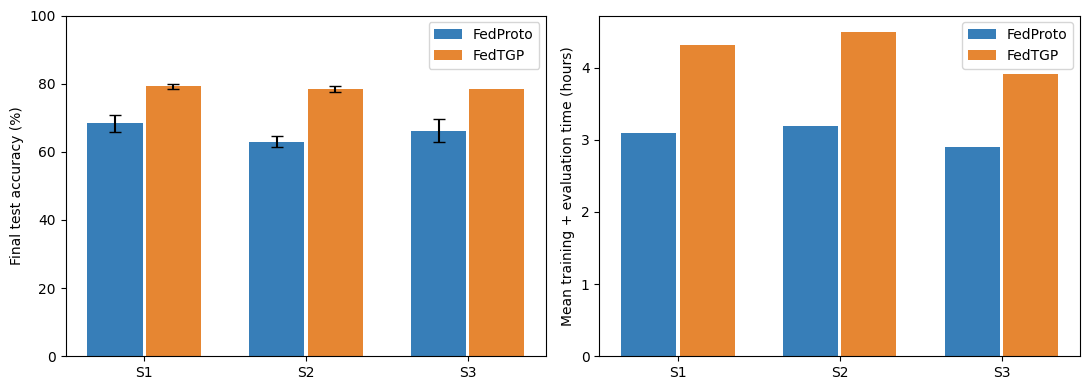

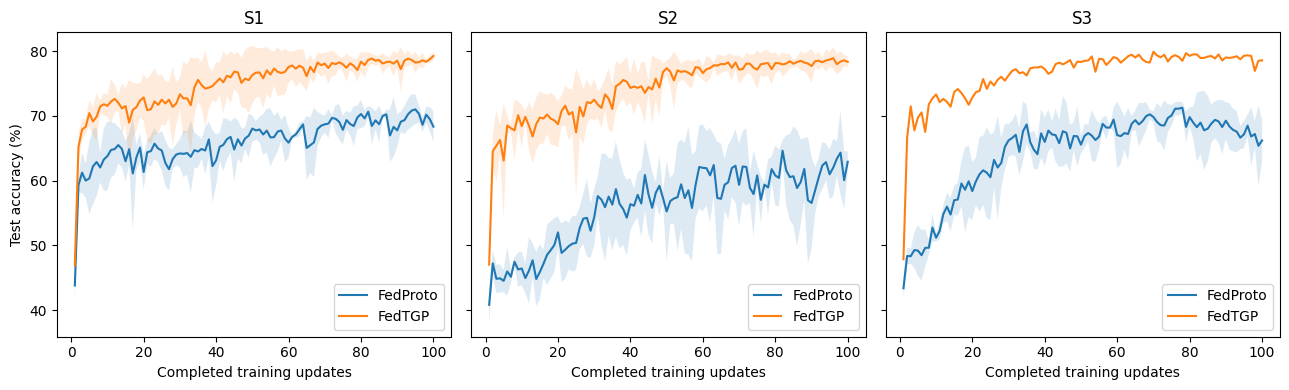

In [ ]:
# COMPARISON TABLES AND GRAPHS

exp.summarize(ROOT)
